# 07 · Análisis del monitoreo

PSet 4, sección 6. Lee lo que dejó la simulación de producción y lo analiza por capa: **sistema** (latencia, errores), **datos** (PSI, KS, χ², z de mercado) y **modelo** (salida, MAE con un lote de retraso, Sharpe de 12 lotes). Fuente, en orden de preferencia:

1. `docs/monitoreo.csv`, `docs/alertas.csv`, `docs/reentrenamientos.csv`: exportados de `PORTAFOLIO_P4.PRODUCCION` después de correr `produccion_lotes` en Kestra;
2. si no existen, `docs/simulacion/*_simulacion.csv` (notebook 06, mismo código fuera de Kestra).

In [1]:
from pathlib import Path
import json, os, sys
RAIZ = Path.cwd().resolve()
while not (RAIZ / 'monitoreo').exists():
    RAIZ = RAIZ.parent
for p in (RAIZ, RAIZ / 'modelos'):
    sys.path.insert(0, str(p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.datos import cargar
from src.pipeline import dividir, preparar, FEATURES
from monitoreo.alertas import PLANTILLA, UMBRAL_MAE, MAE_CV, DE_CV
from monitoreo.deriva import Referencia
from monitoreo.simulacion import LOTES_DERIVA, lote_del_mes, meses_produccion
DOCS = RAIZ / 'docs'; FIG = DOCS / 'figuras'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
if (DOCS / 'monitoreo.csv').exists():
    mon = pd.read_csv(DOCS / 'monitoreo.csv'); mon.columns = mon.columns.str.lower()
    if 'metricas' in mon:
        mon = pd.DataFrame([json.loads(x) | {'modelo_version': v} for x, v in zip(mon['metricas'], mon['modelo_version'])])
    al = pd.read_csv(DOCS / 'alertas.csv'); al.columns = al.columns.str.lower()
    re = pd.read_csv(DOCS / 'reentrenamientos.csv'); re.columns = re.columns.str.lower()
    fuente = 'Snowflake (Kestra)'
else:
    mon = pd.read_csv(DOCS / 'simulacion/monitoreo_simulacion.csv')
    al = pd.read_csv(DOCS / 'simulacion/alertas_simulacion.csv')
    re = pd.read_csv(DOCS / 'simulacion/reentrenamientos_simulacion.csv')
    fuente = 'simulación fuera de Kestra (notebook 06)'
mon = mon.sort_values('anio_mes').reset_index(drop=True)
mon['fecha'] = pd.PeriodIndex(mon['anio_mes'].astype(int).astype(str), freq='M').to_timestamp()
print(f'fuente: {fuente}; {len(mon)} lotes, {len(al)} alertas, {len(re)} reentrenamientos')

fuente: simulación fuera de Kestra (notebook 06); 35 lotes, 33 alertas, 5 reentrenamientos


## 1. Plantilla de alertas (metrica, umbral, severidad, acción, responsable)

In [2]:
PLANTILLA

,id,capa,metrica,umbral,ventana,severidad,quien_la_recibe,accion
0,A1,sistema,errores 5xx de la API,> 0,desde el envio del lote,critico,ingeniero de ML,"Revisar logs; si el modelo no carga, el respal..."
1,A2,sistema,latencia p95 de /predecir,> 2.000 ms,desde el envio del lote,alerta,ingeniero de ML,Revisar memoria del contenedor y tamano del lo...
2,A3,datos,filas no enviadas por nulos o rechazadas (422)...,> 2 % o >= 1,1 lote,alerta,ingeniero de datos,Revisar la ingesta y los tests de dbt del mes;...
3,A4,datos,features por accion con PSI sobre su umbral cr...,>= 5,1 lote,critico,cientifico de datos,Diagnosticar: error de captura (comparar con l...
4,A5,datos,features de mercado con |z| frente a la histor...,> 3 (>= 1 feature),1 lote,alerta,cientifico de datos,Mes atipico: revisar el tope de volatilidad; i...
5,A6,modelo,"media o dispersion de las predicciones, |z| fr...",> 3,1 lote,alerta,cientifico de datos,Revisar que sigan 10 incluidas y la estabilida...
6,A7,modelo,MAE de cada lote etiquetado,> 0.0801 (media CV + 1 de),2 lotes etiquetados seguidos,critico,cientifico de datos,Deriva de concepto: dispara reentrenamiento.ym...
7,A8,negocio,Sharpe del portafolio menos Sharpe de B5,"< -0,5",12 lotes etiquetados,critico,responsable del producto,Criterio de retirada R1: interruptor de respal...
8,A9,negocio,Sharpe del portafolio menos Sharpe de la opera...,"< -0,5",12 lotes etiquetados,critico,responsable del producto,Criterio de retirada R6: el asesor opera con l...


## 2. Umbrales de deriva calibrados con el entrenamiento

El PSI de un mes de entrenamiento contra todo el entrenamiento no es 0. Para cada feature se toma el p95 y el p99 de los 132 meses de 2013-2023, con pisos 0,10 y 0,25.

In [3]:
obt, _ = cargar(RAIZ / 'modelos/data/obt_p4.parquet')
entrenamiento, _ = dividir(preparar(obt))
ref = Referencia(entrenamiento, FEATURES)
ref.umbrales.sort_values('umbral_critico', ascending=False).round(3)

,psi_p95_hist,psi_p99_hist,umbral_alerta,umbral_critico
feature,,,,
vol_63d,2.281,8.174,2.281,8.174
rango_log_hl_prom_63d,3.056,7.641,3.056,7.641
cambio_rango_log_hl_21_63,5.185,7.497,5.185,7.497
cambio_rango_log_hl_mes,4.591,7.439,4.591,7.439
rango_log_hl_mes,3.589,5.866,3.589,5.866
rango_log_hl_prom_21d,3.522,5.855,3.522,5.855
vol_garman_klass_21d,3.234,5.836,3.234,5.836
vol_parkinson_21d,3.362,5.710,3.362,5.710
vol_apertura_21d,2.825,5.200,2.825,5.200


## 3. PSI por feature y lote

,202312,202401,202402,202403,202404,202405,202406,202407,202408,202409,202410,202411,202412,202501,202502,...,202508,202509,202510,202511,202512,202601,202602,202603,202604,202605,202606,202607,202608,202609,202610
features_criticas,1,0,1,1,0,0,2,0,0,1,1,2,3,2,2,...,1,1,1,1,1,1,2,1,3,3,3,2,2,3,3


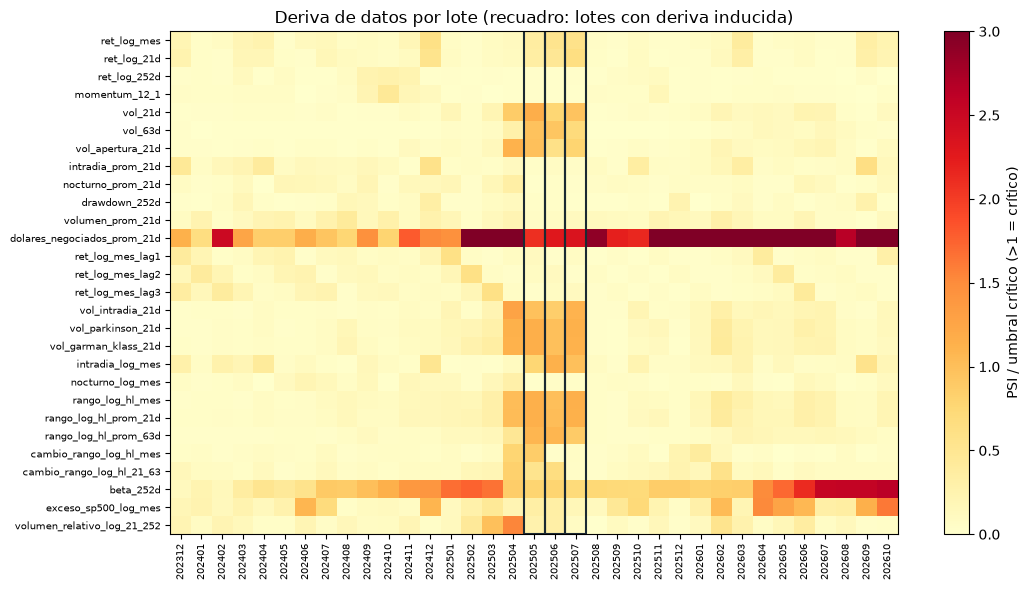

In [4]:
filas = []
for mes in meses_produccion(obt):
    d = ref.evaluar(lote_del_mes(obt, mes))
    d = d[d['tipo'] == 'numerica'].set_index('feature')
    filas.append((d['psi'] / d['umbral_critico']).rename(mes))
rel = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(rel.T.clip(upper=3), aspect='auto', cmap='YlOrRd', vmin=0, vmax=3)
ax.set_yticks(range(len(rel.columns))); ax.set_yticklabels(rel.columns, fontsize=7)
ax.set_xticks(range(len(rel))); ax.set_xticklabels([str(m) for m in rel.index], rotation=90, fontsize=7)
for i, m in enumerate(rel.index):
    if m in LOTES_DERIVA:
        ax.add_patch(plt.Rectangle((i - .5, -.5), 1, len(rel.columns), fill=False, ec='#1B2A33', lw=1.5))
fig.colorbar(im, ax=ax, label='PSI / umbral crítico (>1 = crítico)')
ax.set_title('Deriva de datos por lote (recuadro: lotes con deriva inducida)')
fig.tight_layout(); fig.savefig(FIG / 'psi_por_lote.png', dpi=150)
rel.gt(1).sum(axis=1).rename('features_criticas').to_frame().T

## 4. Rendimiento con un lote de retraso frente a la validación cruzada

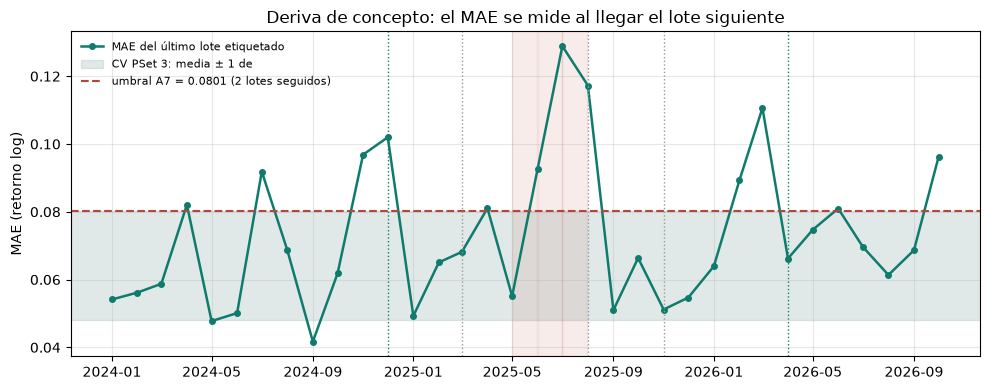

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mon['fecha'], mon['mae_ultimo'], 'o-', color='#0F7B6C', ms=4, lw=1.8, label='MAE del último lote etiquetado')
ax.axhspan(MAE_CV - DE_CV, MAE_CV + DE_CV, color='#9DB8B3', alpha=0.3, label='CV PSet 3: media ± 1 de')
ax.axhline(UMBRAL_MAE, color='#B5473A', ls='--', label=f'umbral A7 = {UMBRAL_MAE:.4f} (2 lotes seguidos)')
for m in LOTES_DERIVA:
    t = pd.Period(str(m), freq='M').to_timestamp(); ax.axvspan(t, t + pd.offsets.MonthEnd(1), color='#B5473A', alpha=0.1)
for r in re.itertuples():
    t = pd.Period(str(int(r.anio_mes_llegada)), freq='M').to_timestamp()
    ax.axvline(t, color='#0F7B6C' if str(r.aprobado).lower() == 'true' else '#999999', ls=':', lw=1)
ax.set_ylabel('MAE (retorno log)'); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=.3)
ax.set_title('Deriva de concepto: el MAE se mide al llegar el lote siguiente')
fig.tight_layout(); fig.savefig(FIG / 'mae_por_lote.png', dpi=150)

## 5. Negocio: Sharpe de 12 lotes del portafolio frente a B5 (A8) y a la operación manual (A9)

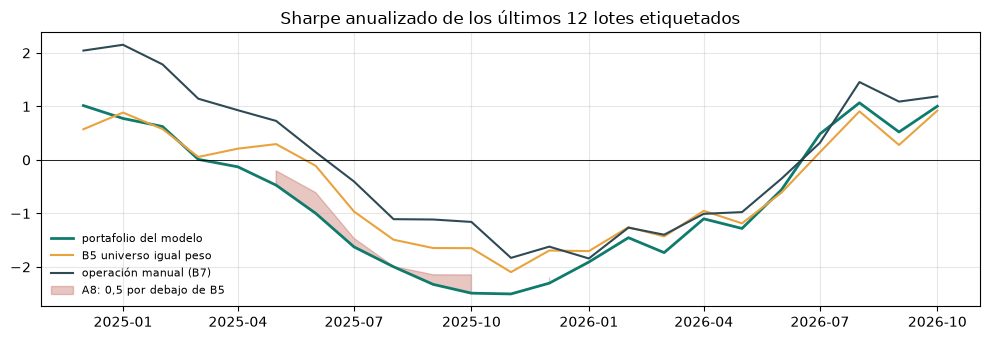

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(mon['fecha'], mon['sharpe_12'], color='#0F7B6C', lw=2, label='portafolio del modelo')
ax.plot(mon['fecha'], mon['sharpe_b5_12'], color='#E8A33D', lw=1.5, label='B5 universo igual peso')
if 'sharpe_manual_12' in mon:
    ax.plot(mon['fecha'], mon['sharpe_manual_12'], color='#2E4A55', lw=1.5, label='operación manual (B7)')
ax.fill_between(mon['fecha'], mon['sharpe_12'], mon['sharpe_b5_12'] - 0.5, where=mon['sharpe_12'] < mon['sharpe_b5_12'] - 0.5, color='#B5473A', alpha=.3, label='A8: 0,5 por debajo de B5')
ax.axhline(0, color='k', lw=.6); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=.3)
ax.set_title('Sharpe anualizado de los últimos 12 lotes etiquetados')
fig.tight_layout(); fig.savefig(FIG / 'sharpe_12_lotes.png', dpi=150)

## 6. Alertas por lote y diagnóstico

In [7]:
tabla = al.groupby('anio_mes')['id_alerta'].apply(lambda x: ', '.join(sorted(set(x)))).rename('alertas')
cols = ['anio_mes', 'modelo_version', 'sintetico', 'n_psi_critico', 'feature_psi_max', 'n_mercado_z3', 'mae_ultimo', 'mae_penultimo', 'sharpe_12', 'sharpe_b5_12', 'sharpe_manual_12']
diag = mon[cols].merge(tabla, on='anio_mes', how='left').fillna({'alertas': ''})

def diagnostico(r):
    a = r['alertas']
    if r['sintetico']:
        return 'Deriva inducida (crisis sintética): datos y concepto cambian; reentrenar no ayuda, revisar retirada (A8).'
    if 'A5' in a:
        return 'Mercado atípico frente a 2013-2023 (tasa libre de riesgo ~5 %): deriva real de una variable de mercado; sin efecto en el MAE.'
    if 'A4' in a:
        return 'Choque real de volatilidad (abril 2025, aranceles): deriva de datos sin caída del MAE; no se reentrena por deriva.'
    if 'A7' in a and 'A8' in a:
        return 'Rendimiento bajo y portafolio peor que B5: arrastre de la crisis; reentrenamiento y revisión humana.'
    if 'A7' in a:
        return 'Deriva de concepto: dos lotes etiquetados seguidos con MAE sobre media CV + 1 de; dispara reentrenamiento (enfriamiento de 3 lotes).'
    if 'A9' in a and 'A8' not in a:
        return 'El modelo queda 0,5 de Sharpe bajo la operación manual (A9): criterio R6, operar con la regla y dejar el modelo en paralelo.'
    if 'A8' in a:
        return 'Criterio de retirada R1: Sharpe 12 lotes 0,5 bajo B5; revisar con el asesor y considerar el respaldo.'
    if 'A6' in a:
        return 'La salida del modelo se movió (dispersión de las predicciones): revisar que el top 10 siga siendo estable.'
    return 'Sin alertas.'
diag['diagnostico'] = diag.apply(diagnostico, axis=1)
diag.to_csv(DOCS / 'diagnostico_lotes.csv', index=False)
diag[diag['alertas'] != ''][['anio_mes', 'modelo_version', 'alertas', 'feature_psi_max', 'mae_ultimo', 'diagnostico']].round(3)

,anio_mes,modelo_version,alertas,feature_psi_max,mae_ultimo,diagnostico
4,202404,1,A5,intradia_log_mes,0.082,Mercado atípico frente a 2013-2023 (tasa libre...
5,202405,1,A5,ret_log_mes_lag1,0.048,Mercado atípico frente a 2013-2023 (tasa libre...
7,202407,1,A5,cambio_rango_log_hl_21_63,0.092,Mercado atípico frente a 2013-2023 (tasa libre...
8,202408,1,A5,vol_garman_klass_21d,0.069,Mercado atípico frente a 2013-2023 (tasa libre...
12,202412,r1,"A7, A9",ret_log_21d,0.102,Deriva de concepto: dos lotes etiquetados segu...
13,202501,r1,A9,ret_log_mes_lag1,0.049,"El modelo queda 0,5 de Sharpe bajo la operació..."
14,202502,r1,A9,ret_log_mes_lag2,0.065,"El modelo queda 0,5 de Sharpe bajo la operació..."
15,202503,r1,A9,vol_garman_klass_21d,0.068,"El modelo queda 0,5 de Sharpe bajo la operació..."
16,202504,r1,"A4, A9",vol_garman_klass_21d,0.081,"Choque real de volatilidad (abril 2025, arance..."
17,202505,r1,"A4, A8, A9",rango_log_hl_prom_63d,0.055,Deriva inducida (crisis sintética): datos y co...


## 7. Tabla de diagnóstico (PDF 6.2) y falsas alarmas

| Entradas | Desempeño | Diagnóstico | Acción en el proyecto |
|---|---|---|---|
| Cambian | Se mantiene | Deriva de datos sin impacto | Alerta A4/A5 de aviso; diagnosticar captura vs. mercado; **no** se reentrena (2024: tasa ~5 %; abril 2025: aranceles). |
| Cambian | Cae | Deriva de datos con impacto | A4 + A7: reentrenar con los lotes etiquetados; si el challenger no gana, criterio de retirada (A8 → respaldo). Caso: la crisis inducida. |
| Estables | Cae | Deriva conceptual | A7 sin A4: reentrenar (fines de 2024, marzo de 2026). |

El PDF pide que los lotes sin alterar no disparen la alerta de deriva. La tabla siguiente cuenta las alertas en lotes reales.

In [8]:
reales = diag[~diag['sintetico'].astype(bool) & (diag['alertas'] != '')]
falsas = reales.assign(alerta=reales['alertas'].str.split(', ')).explode('alerta')
falsas.groupby('alerta')['anio_mes'].apply(lambda x: ', '.join(map(str, x))).rename('lotes reales con la alerta').to_frame()

,lotes reales con la alerta
alerta,
A4,202504
A5,"202404, 202405, 202407, 202408"
A7,"202412, 202508, 202603"
A8,"202508, 202509, 202510, 202512"
A9,"202412, 202501, 202502, 202503, 202504, 202508..."


**Lectura y ajuste de umbrales.**
- **A4 (PSI) en 2025-04** no es falsa en sentido estricto: el choque de aranceles movió de verdad la volatilidad. Con el umbral en ≥ 9 features críticas desaparecería, pero también la detección del lote inducido 2025-06 (5). Se deja en 5 y se documenta como deriva real sin impacto.
- **A5 (tasa libre de riesgo) en 2024** es una falsa alarma para el modelo: el entrenamiento (2013-2023) tuvo tasas casi cero. Ajuste propuesto: medir el z contra los últimos 36 meses y no contra todo el entrenamiento, o dejar A5 como informativa sin correo.
- **A7 en lotes reales** responde a meses con caídas reales (fines de 2024, febrero-marzo de 2026): no es falsa, es deriva conceptual transitoria; el enfriamiento evita reentrenar cada mes.
- **A8 después de la crisis** se mantiene mientras la ventana de 12 lotes incluye los meses sintéticos: es un efecto de la ventana, no un problema nuevo.

## 8. Reentrenamientos

In [9]:
re

,anio_mes_llegada,disparador,version_champion,version_challenger,aprobado,lotes_evaluacion,hasta_anio_mes,filas_entrenamiento,mae_champion,mae_challenger,retorno_champion,retorno_challenger,promueve,segundos,motivo_regla
0,202412,calendario (12 lotes),1,r1,True,[202411],202410,50355,0.102000,0.086594,-0.056693,-0.035980,True,0.339112,cumple la regla
1,202503,rendimiento (A7),r1,r2,False,[202502],202501,51360,0.068176,0.070316,0.000184,0.016424,False,0.333367,su MAE es peor que el del champion
2,202508,rendimiento (A7),r1,r3,False,[202507],202506,53029,0.117263,0.106471,-0.088640,-0.089588,False,0.317265,no gana suficiente dinero
3,202511,rendimiento (A7),r1,r4,False,[202510],202509,54028,0.051172,0.050911,0.037717,0.029179,False,0.321353,no gana suficiente dinero
4,202604,rendimiento (A7),r1,r5,True,[202603],202602,55705,0.066206,0.065508,0.040775,0.072766,True,0.314849,cumple la regla


## 9. Conclusiones del monitoreo

- La deriva de **datos** es frecuente y casi nunca se traduce en peor MAE: en 2024 la tasa libre de riesgo (≈5 %) está lejos de su historia (A5) y en abril de 2025 el choque de volatilidad mueve 8 features (A4), pero el MAE no sube. Por eso la deriva sola no dispara el reentrenamiento.
- La deriva de **concepto** (A7) sí aparece: a fines de 2024, tras la crisis inducida y en marzo de 2026, dos lotes seguidos superan la media CV + 1 de.
- La métrica que importa al cliente es la de **negocio** (A8): durante la crisis el portafolio queda más de 0,5 de Sharpe bajo B5. Ese es el criterio de retirada R1, que lleva al interruptor de respaldo.